# Model comparison — Attention U-Net vs CNN (scratch) vs ViT-B/16
All three use the identical stratified split (seed 42: train 12,716 / val 1,696 / test 2,544), the same 5 classes, class-weighted focal loss and early stopping on val loss.

* **Attention U-Net** — numbers from its original training run (`notebooks/02_train_class_specific_aug.ipynb`, outputs preserved; not re-run).
* **CNN** and **ViT-B/16** — trained here on the RTX 5070 Ti (`02_…`, `03_…`).

~51% of images are No_DR, so **balanced accuracy, macro-F1 and Cohen's kappa** are the headline metrics.

In [1]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve, auc, balanced_accuracy_score
from scipy.stats import chi2
from IPython.display import display, Markdown
OUT_DIR = r"C:\Users\pooja\Desktop\dp\model_comparison"
RES = os.path.join(OUT_DIR, "results")
R = {k: json.load(open(os.path.join(RES, f))) for k, f in
     [("Attention U-Net", "attention_unet.json"), ("CNN (scratch)", "cnn_scratch.json"), ("ViT-B/16", "vit_b16.json")]}
CLASSES = ["Mild", "Moderate", "No_DR", "Proliferate_DR", "Severe"]
FULL = [k for k, r in R.items() if "y_prob" in r]          # models with per-image predictions
for k in FULL:
    r = R[k]; r["y"] = np.array(r["y_true"]); r["p"] = np.array(r["y_prob"]); r["pred"] = r["p"].argmax(1)
    p, rc, f, s = precision_recall_fscore_support(r["y"], r["pred"], labels=range(5), zero_division=0)
    r["per_class"] = {c: [p[i], rc[i], f[i], int(s[i])] for i, c in enumerate(CLASSES)}
# same split check: per-class test support must match the U-Net run
sup = {k: [r["per_class"][c][3] for c in CLASSES] for k, r in R.items()}
print(pd.DataFrame(sup, index=CLASSES))
assert len({tuple(v) for v in sup.values()}) == 1, "test splits differ!"
print("✓ identical test set composition for all three models")

                Attention U-Net  CNN (scratch)  ViT-B/16
Mild                        241            241       241
Moderate                    661            661       661
No_DR                      1300           1300      1300
Proliferate_DR              204            204       204
Severe                      138            138       138
✓ identical test set composition for all three models


## 1. Headline metrics (test set, 2,544 images)

,Accuracy %,Balanced acc %,Macro F1,Cohen kappa,Quadratic kappa,Macro AUC,Params (M),Epochs,Train time (min),Hardware / framework
Model,,,,,,,,,,
Attention U-Net,78.540,67.850,0.640,0.680,—,—,74.800,28,113.717,TensorFlow 2.10 (2 GPUs)
CNN (scratch),71.777,61.763,0.551,0.585,0.445,0.919,4.847,40,58.081,PyTorch 2.11.0+cu128
ViT-B/16,87.854,81.589,0.795,0.816,0.755,0.974,85.803,15,16.961,PyTorch 2.11.0+cu128


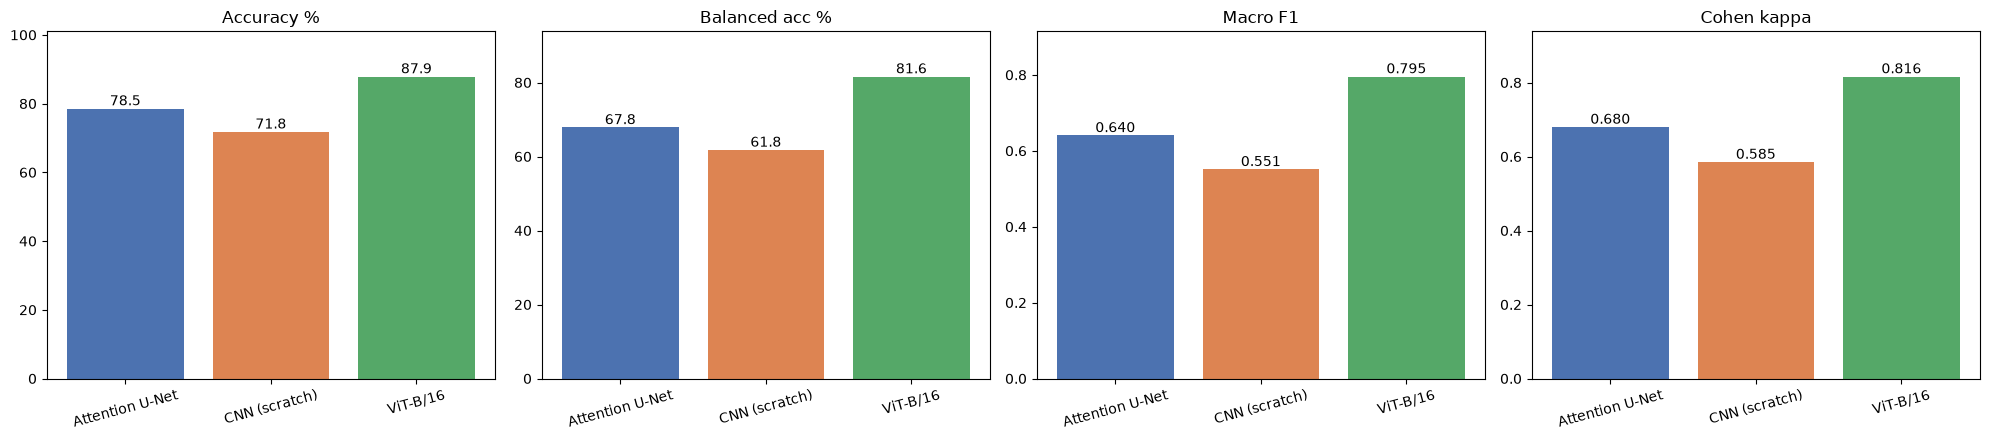

In [2]:
COLORS = {"Attention U-Net": "#4C72B0", "CNN (scratch)": "#DD8452", "ViT-B/16": "#55A868"}
rows = []
for k, r in R.items():
    t = r["test"]
    rows.append({"Model": k, "Accuracy %": 100*t["accuracy"], "Balanced acc %": 100*t["balanced_accuracy"],
                 "Macro F1": t["macro_f1"], "Cohen kappa": t["kappa"],
                 "Quadratic kappa": t.get("quadratic_kappa", np.nan), "Macro AUC": t.get("macro_auc", np.nan),
                 "Params (M)": r["params"]/1e6, "Epochs": r["epochs_trained"], "Train time (min)": r["train_time_s"]/60,
                 "Hardware / framework": r["framework"]})
table = pd.DataFrame(rows).set_index("Model")
table.to_csv(os.path.join(RES, "comparison_table.csv"))
display(table.style.format(precision=3, na_rep="—").highlight_max(subset=table.columns[:6], color="#c6efce"))

ms = ["Accuracy %", "Balanced acc %", "Macro F1", "Cohen kappa"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for a, m in zip(axes, ms):
    v = table[m]; b = a.bar(v.index, v.values, color=[COLORS[k] for k in v.index])
    a.set_title(m); a.tick_params(axis="x", rotation=15); a.set_ylim(0, v.max()*1.15); a.bar_label(b, fmt="%.3f" if v.max() <= 1 else "%.1f")
plt.tight_layout(); plt.savefig(os.path.join(RES, "metrics_bar.png"), dpi=200); plt.show()

## 2. Per-class performance — the minority grades are what matter clinically

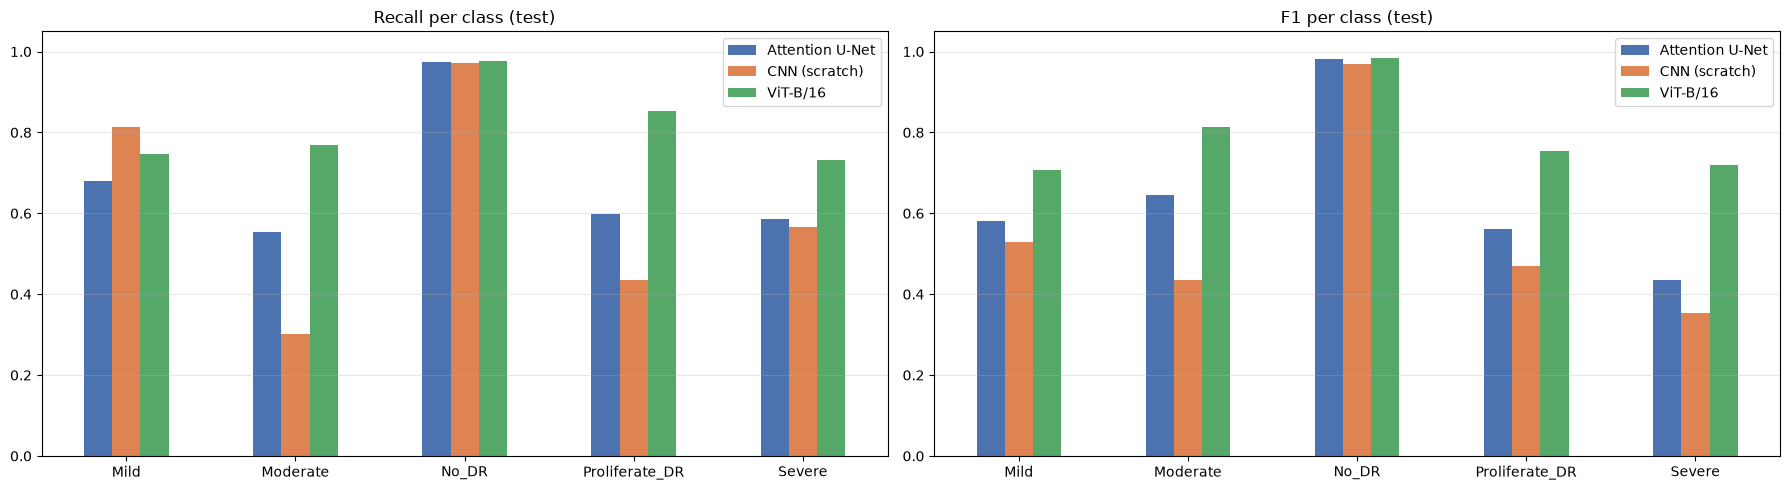

**Recall**

,Attention U-Net,CNN (scratch),ViT-B/16
Mild,0.680,0.813,0.747
Moderate,0.554,0.301,0.770
No_DR,0.973,0.972,0.978
Proliferate_DR,0.598,0.436,0.853
Severe,0.587,0.565,0.732


**F1**

,Attention U-Net,CNN (scratch),ViT-B/16
Mild,0.581,0.530,0.707
Moderate,0.644,0.434,0.814
No_DR,0.981,0.968,0.983
Proliferate_DR,0.562,0.470,0.753
Severe,0.434,0.353,0.719


In [3]:
rec = pd.DataFrame({k: [r["per_class"][c][1] for c in CLASSES] for k, r in R.items()}, index=CLASSES)
f1 = pd.DataFrame({k: [r["per_class"][c][2] for c in CLASSES] for k, r in R.items()}, index=CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
rec.plot.bar(ax=ax[0], rot=0, color=[COLORS[k] for k in rec.columns]); ax[0].set_title("Recall per class (test)")
f1.plot.bar(ax=ax[1], rot=0, color=[COLORS[k] for k in f1.columns]); ax[1].set_title("F1 per class (test)")
for a in ax: a.set_ylim(0, 1.05); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(RES, "per_class.png"), dpi=200); plt.show()
display(Markdown("**Recall**")); display(rec.style.format("{:.3f}").highlight_max(axis=1, color="#c6efce"))
display(Markdown("**F1**")); display(f1.style.format("{:.3f}").highlight_max(axis=1, color="#c6efce"))

## 3. Confusion matrices and ROC (CNN, ViT)
The U-Net's confusion matrix and ROC curves are in `notebooks/02_train_class_specific_aug.ipynb`.

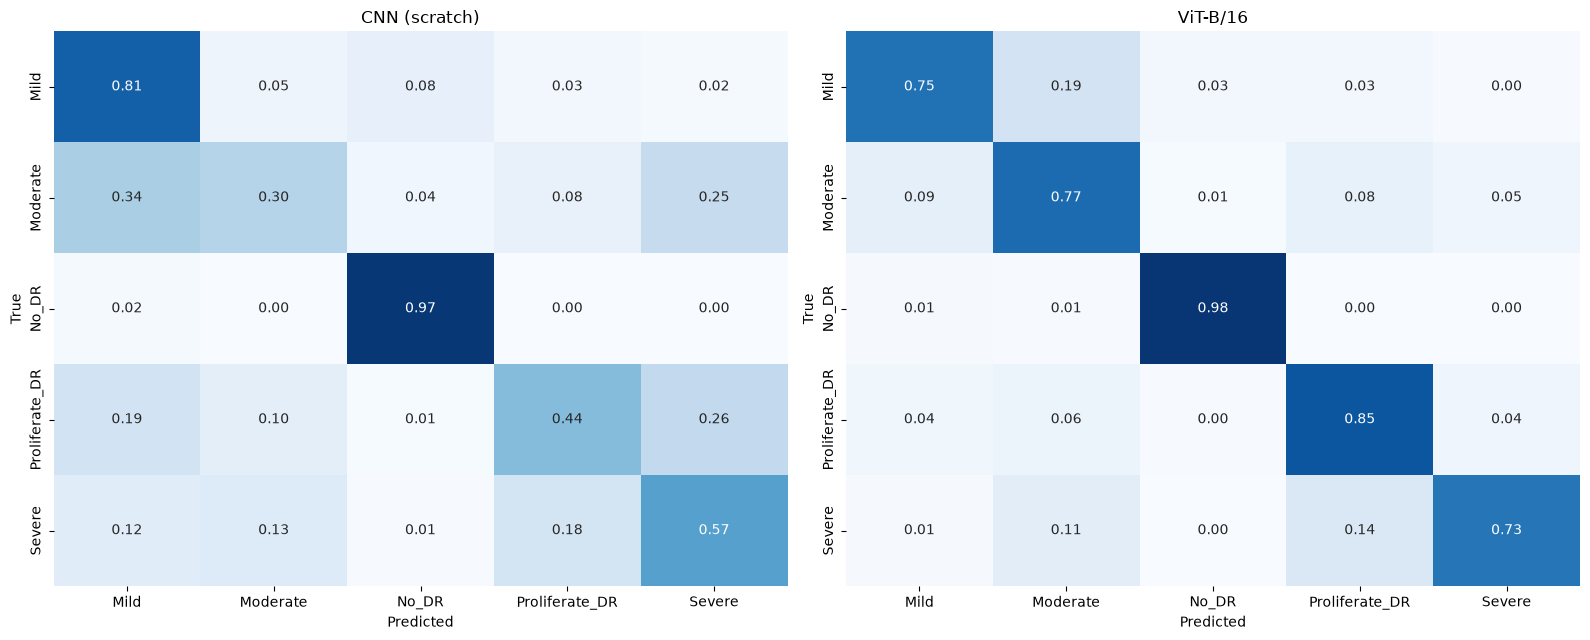

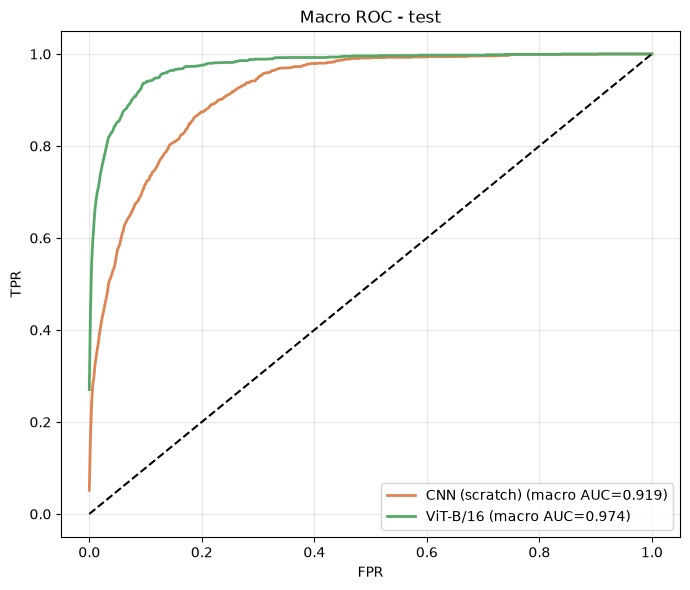

In [4]:
fig, axes = plt.subplots(1, len(FULL), figsize=(8*len(FULL), 6.5))
for a, k in zip(np.atleast_1d(axes), FULL):
    cm = confusion_matrix(R[k]["y"], R[k]["pred"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(k); a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig(os.path.join(RES, "confusion_matrices.png"), dpi=200); plt.show()

plt.figure(figsize=(7, 6)); g = np.linspace(0, 1, 500)
for k in FULL:
    m = np.mean([np.interp(g, *roc_curve(R[k]["y"] == i, R[k]["p"][:, i])[:2]) for i in range(5)], 0)
    plt.plot(g, m, lw=2, color=COLORS[k], label=f"{k} (macro AUC={auc(g, m):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.grid(alpha=.3); plt.title("Macro ROC - test")
plt.tight_layout(); plt.savefig(os.path.join(RES, "roc_macro.png"), dpi=200); plt.show()

## 4. Learning curves

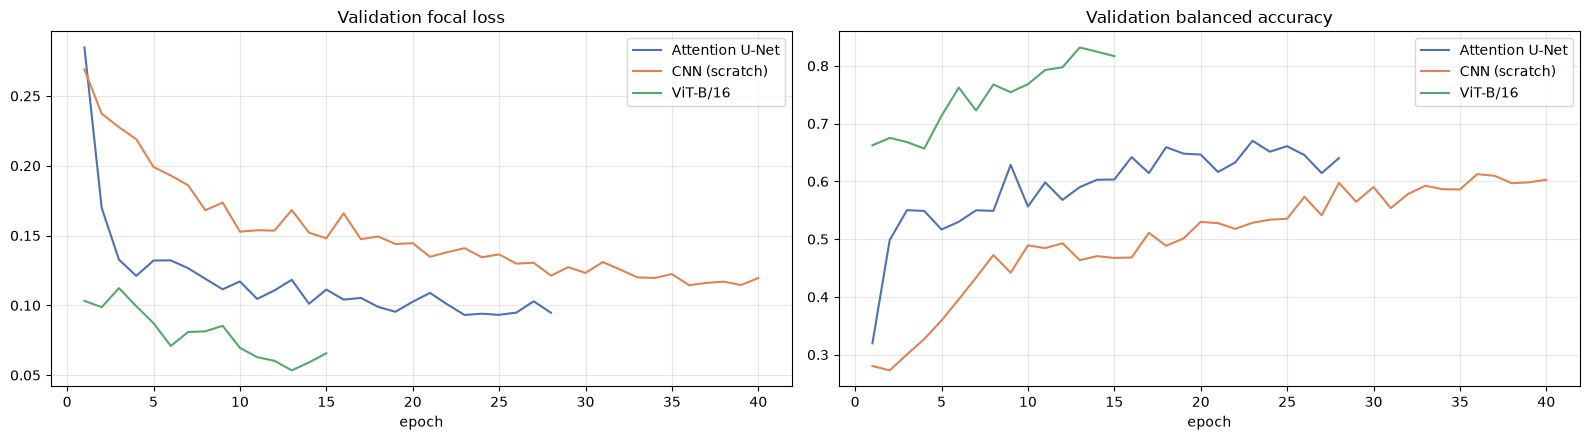

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for k, r in R.items():
    h = r["history"]; ax[0].plot(range(1, len(h["val_loss"])+1), h["val_loss"], label=k, color=COLORS[k])
    ax[1].plot(range(1, len(h["val_balanced_accuracy"])+1), h["val_balanced_accuracy"], label=k, color=COLORS[k])
ax[0].set_title("Validation focal loss"); ax[1].set_title("Validation balanced accuracy")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(RES, "learning_curves.png"), dpi=200); plt.show()

## 5. Is the CNN vs ViT gap real? (paired tests on the same 2,544 images)

In [6]:
if len(FULL) == 2:
    a, b = FULL; y = R[a]["y"]
    ca, cb = R[a]["pred"] == y, R[b]["pred"] == y; n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = 1 - chi2.cdf((abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1), 1)
    print(f"McNemar: {a} right/{b} wrong = {n01}, {b} right/{a} wrong = {n10}, p = {p:.2e}")
rng = np.random.default_rng(0)
ci = {}
for k in FULL:
    y, pr = R[k]["y"], R[k]["pred"]
    s = [balanced_accuracy_score(y[i], pr[i]) for i in rng.integers(0, len(y), (1000, len(y)))]
    ci[k] = np.percentile(s, [2.5, 97.5])
display(pd.DataFrame(ci, index=["BalAcc 2.5%", "BalAcc 97.5%"]).T.style.format("{:.3f}"))
print("U-Net reported balanced accuracy:", R["Attention U-Net"]["test"]["balanced_accuracy"])

McNemar: CNN (scratch) right/ViT-B/16 wrong = 94, ViT-B/16 right/CNN (scratch) wrong = 503, p = 0.00e+00


,BalAcc 2.5%,BalAcc 97.5%
CNN (scratch),0.593,0.642
ViT-B/16,0.793,0.837


U-Net reported balanced accuracy: 0.6785


## 6. Summary (generated from the numbers above)

In [7]:
best = table["Balanced acc %"].idxmax()
L = [f"**Best on balanced accuracy: {best}** — {table.loc[best, 'Balanced acc %']:.2f}% balanced acc, "
     f"kappa {table.loc[best, 'Cohen kappa']:.3f}, macro-F1 {table.loc[best, 'Macro F1']:.3f}.", ""]
for k in table.index:
    w = rec[k].idxmin()
    L.append(f"- **{k}**: {table.loc[k, 'Accuracy %']:.2f}% acc, {table.loc[k, 'Balanced acc %']:.2f}% balanced acc, "
             f"kappa {table.loc[k, 'Cohen kappa']:.3f}; {table.loc[k, 'Params (M)']:.1f}M params, "
             f"{table.loc[k, 'Epochs']} epochs / {table.loc[k, 'Train time (min)']:.0f} min ({table.loc[k, 'Hardware / framework']}); "
             f"weakest class {w} (recall {rec.loc[w, k]:.2f}).")
L.append(f"- Hardest grade overall: **{rec.mean(1).idxmin()}** (mean recall {rec.mean(1).min():.2f}); "
         f"easiest: **{rec.mean(1).idxmax()}** ({rec.mean(1).max():.2f}).")
Markdown("\n".join(L))

C:\Users\pooja\AppData\Local\Temp\ipykernel_90624\968294540.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  L.append(f"- Hardest grade overall: **{rec.mean(1).idxmin()}** (mean recall {rec.mean(1).min():.2f}); "
C:\Users\pooja\AppData\Local\Temp\ipykernel_90624\968294540.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  L.append(f"- Hardest grade overall: **{rec.mean(1).idxmin()}** (mean recall {rec.mean(1).min():.2f}); "
C:\Users\pooja\AppData\Local\Temp\ipykernel_90624\968294540.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  f"easiest: **{rec.mean(1).idxmax()}** ({rec.mean(1).max():.2f}).")
C:\Users\pooja\AppData\Local\Temp\ipykernel_90624\968294540.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  f"easiest: **{rec.mean(1).idxmax()}** ({rec.mean(1).max():.2f}).")


**Best on balanced accuracy: ViT-B/16** — 81.59% balanced acc, kappa 0.816, macro-F1 0.795.

- **Attention U-Net**: 78.54% acc, 67.85% balanced acc, kappa 0.680; 74.8M params, 28 epochs / 114 min (TensorFlow 2.10 (2 GPUs)); weakest class Moderate (recall 0.55).
- **CNN (scratch)**: 71.78% acc, 61.76% balanced acc, kappa 0.585; 4.8M params, 40 epochs / 58 min (PyTorch 2.11.0+cu128); weakest class Moderate (recall 0.30).
- **ViT-B/16**: 87.85% acc, 81.59% balanced acc, kappa 0.816; 85.8M params, 15 epochs / 17 min (PyTorch 2.11.0+cu128); weakest class Severe (recall 0.73).
- Hardest grade overall: **Moderate** (mean recall 0.54); easiest: **No_DR** (0.97).